In [3]:
import os
import time
from datetime import datetime
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, f1_score, normalized_mutual_info_score
from sklearn.preprocessing import LabelEncoder
import cellcharter as cc
import squidpy as sq

In [1]:
model_name = "cellcharter"
latent_key = f"{model_name}_latent"
leiden_resolution = 0.5 # used for Leiden clustering of latent space
random_seed = 0 # used for Leiden clustering
label_cats = ["cell_type", "niche_type"]
cell_type_key =label_cats[0]

In [4]:
sc.set_figure_params(figsize=(6, 6))


/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/scanpy/_settings.py:488: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  IPython.display.set_matplotlib_formats(*ipython_format)
/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


## configure paths

In [11]:
data_folder_path = "../"
benchmarking_folder_path = '../benchmarking/'
figure_folder_path = "../figures_cc/"
result_directory = '../results/'

In [6]:
# Get time of notebook execution for timestamping saved artifacts
now = datetime.now()
current_timestamp = now.strftime("%d%m%Y_%H%M%S")

In [81]:
def run_classifier(adata, labels_cats, dataset_name , n_start_run=1, n_end_run=1):
    scores = []
    for label_cat in labels_cats:
          label_encoder = LabelEncoder()
          labels = np.array(
              label_encoder.fit_transform(adata.obs[label_cat]))
          for run_num in range(n_start_run, n_end_run+1):
              for random_state in range(10):
                np.random.seed(random_state)

                indices = np.arange(adata.X.shape[0])
                np.random.shuffle(indices)
                num_train = int(0.8 * len(indices))
                train_indices = indices[:num_train]
                test_indices = indices[num_train:]
                labels_train = labels[train_indices]
                labels_test = labels[test_indices]
                X = adata.obsm[f"cellcharter_latent_run{run_num}"]
                X_train = X[train_indices]
                X_test = X[test_indices]

                lr_clf = LogisticRegression()
                lr_clf.fit(X_train, labels_train)
                train_predictions = lr_clf.predict(X_train)
                train_f1 = f1_score(labels_train, train_predictions, average="weighted")
                train_score = lr_clf.score(X_train, labels_train)
                test_predictions = lr_clf.predict(X_test)
                test_f1 = f1_score(labels_test, test_predictions, average="weighted")
                test_score = lr_clf.score(X_test, labels_test)
                scores.append({
                            "clf_task": label_cat,
                            "random_state": random_state,
                            "run_number": run_num,
                            "clf_category": "train",
                            "f1_score": train_f1,
                            "accuracy": train_score})

                scores.append({
                            "clf_task": label_cat,
                            "random_state": random_state,
                            "run_number" : run_num,
                            "clf_category": "test",
                            "f1_score": test_f1,
                            "accuracy": test_score})
 
    scores_df = pd.DataFrame(scores)
    os.makedirs(f"{result_directory}/{dataset_name}", exist_ok=True)
    scores_df.to_csv(f"{result_directory}/{dataset_name}/result_classification_cellcharter.csv", index=False, sep='\t')

    

In [84]:
def get_clusters(adata_new, labels, dataset_name, n_start_run=1,
                             n_end_run=8,
                             n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16], cell_type_key = cell_type_key,  plot_latent_umaps= True):
    scores = []
    for label_cat in labels:
          for run_number, n_neighbors in zip(np.arange(n_start_run, n_end_run+1), n_neighbor_list):
            #X = adata.obsm[f"cellcharter_latent_run{run_number}"]
            sc.pp.neighbors(adata_new, n_neighbors=n_neighbors,use_rep= f"cellcharter_latent_run{run_number}")

            sc.tl.leiden(adata=adata_new,
                         resolution=leiden_resolution,
                         random_state=random_seed,
                         key_added=f"latent_{model_name}_run_{str(run_number)}_leiden_{str(leiden_resolution)}")

            nmi_score = normalized_mutual_info_score(adata_new.obs[label_cat], adata_new.obs[f"latent_{model_name}_run_{str(run_number)}_leiden_{str(leiden_resolution)}"])
            ari_score = adjusted_rand_score(adata_new.obs[label_cat], adata_new.obs[f"latent_{model_name}_run_{str(run_number)}_leiden_{str(leiden_resolution)}"])
            scores.append({
                            "n_neighbors": n_neighbors,
                            "run_number": run_number,
                            "clf_category": label_cat,
                            "nmi_score": nmi_score,
                            "ari_score": ari_score})
            
    if plot_latent_umaps:
          os.makedirs(f"{figure_folder_path}/{dataset_name}", exist_ok=True)
          for run_number, n_neighbors in zip(np.arange(n_start_run, n_end_run+1), n_neighbor_list):
            # Use  latent space for UMAP generation
              # sc.pp.neighbors(adata_new,
              #               use_rep=latent_key,
              #               n_neighbors=n_neighbors)
              sc.tl.umap(adata_new)
              fig = sc.pl.umap(adata_new,
                             color=[label_cat],
                             title="Latent Space with Cell Types: cell_charter",
                             return_fig=True)
              
              fig.savefig(f"{figure_folder_path}/latent_{model_name}"
                        f"_cell_types_run{run_number}.png",
                        bbox_inches="tight")

              # Create subplot of latent Leiden cluster annotations in physical and latent space
              fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(6, 12))
              title = fig.suptitle(t="Latent and Physical Space with Leiden Clusters: cellcharter")
              sc.pl.umap(adata=adata_new,
                       color=[f"latent_{model_name}_run_{str(run_number)}_leiden_{str(leiden_resolution)}"],
                       title=f"Latent Space with Leiden Clusters",
                       ax=axs[0],
                       show=False)
              sq.pl.spatial_scatter(adata=adata_new,
                                  color=[f"latent_{model_name}_run_{str(run_number)}_leiden_{str(leiden_resolution)}"],
                                  title=f"Physical Space with Leiden Clusters",
                                  shape=None,
                                  ax=axs[1])

            # Create and position shared legend
              handles, labels = axs[0].get_legend_handles_labels()
              lgd = fig.legend(handles, labels, bbox_to_anchor=(1.25, 0.9185))
              axs[0].get_legend().remove()
              axs[1].get_legend().remove()

            # Adjust, save and display plot
              plt.subplots_adjust(wspace=0, hspace=0.2)
              fig.savefig(f"{figure_folder_path}/latent_physical_comparison_"
                        f"{model_name}_run{run_number}.png",
                        bbox_extra_artists=(lgd, title),
                        bbox_inches="tight")
              plt.show()

 
    scores_df = pd.DataFrame(scores)
    os.makedirs(f"{result_directory}/{dataset_name}", exist_ok=True)
    scores_df.to_csv(f"{result_directory}/{dataset_name}/result_clustering.csv", index=False, sep='\t')


In [85]:

def train_cellcharter_models(adata, scvi_adata_file, dataset_name,
                             cell_type_key,
                             adata_new=None,
                             n_start_run=1,
                             n_end_run=8,
                             n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16],
                             plot_latent_umaps=False):
    # Configure figure folder path
    dataset_figure_folder_path = f"{figure_folder_path}/{dataset_name}/single_sample_method_benchmarking/" \
                                 f"{model_name}/{current_timestamp}"
    os.makedirs(dataset_figure_folder_path, exist_ok=True)
    
    # Create new adata to store results from training runs in storage-efficient way
    if adata_new is None:
        adata_original = adata
        adata_new = sc.AnnData(sp.csr_matrix(
            (adata_original.shape[0], adata_original.shape[1]),
            dtype=np.float32))
        adata_new.var_names = adata_original.var_names
        adata_new.obs_names = adata_original.obs_names
        adata_new.obs["cell_type"] = adata_original.obs[cell_type_key].values
        adata_new.obsm["spatial"] = adata_original.obsm["spatial"]


        del(adata_original)
    
    for run_number, n_neighbors in zip(np.arange(n_start_run, n_end_run+1), n_neighbor_list):
        # n_neighbors is here only used for the latent neighbor graph construction used for
        # UMAP generation and clustering as scVI is not a spatial method
        
        # Load trained SCVI results
        adata = sc.read_h5ad(scvi_adata_file)

        start_time = time.time()

        adata.obsm["latent_scvi"] = adata.obsm[f"scvi_latent_run{run_number}"].astype(np.float32)



        # Compute spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type="generic",
                                spatial_key="spatial",
                                n_neighs=n_neighbors)

        # Use CellCharter as per tutorial
        cc.gr.remove_long_links(adata)
        cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep="latent_scvi", out_key=latent_key)
        
        # Measure time for model training
        end_time = time.time()
        elapsed_time = end_time - start_time
        hours, rem = divmod(elapsed_time, 3600)
        minutes, seconds = divmod(rem, 60)

        
        if plot_latent_umaps:
            # Use scVI latent space for UMAP generation
            sc.pp.neighbors(adata,
                            use_rep=latent_key,
                            n_neighbors=n_neighbors)
            sc.tl.umap(adata)
            fig = sc.pl.umap(adata,
                             color=[cell_type_key],
                             title="Latent Space with Cell Types: scVI",
                             return_fig=True)
            fig.savefig(f"{dataset_figure_folder_path}/latent_{model_name}"
                        f"_cell_types_run{run_number}.png",
                        bbox_inches="tight")

            # Compute latent Leiden clustering
            sc.tl.leiden(adata=adata,
                         resolution=leiden_resolution,
                         random_state=random_seed,
                         key_added=f"latent_{model_name}_leiden_{str(leiden_resolution)}")

            # Create subplot of latent Leiden cluster annotations in physical and latent space
            fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(6, 12))
            title = fig.suptitle(t="Latent and Physical Space with Leiden Clusters: scVI")
            sc.pl.umap(adata=adata,
                       color=[f"latent_{model_name}_leiden_{str(leiden_resolution)}"],
                       title=f"Latent Space with Leiden Clusters",
                       ax=axs[0],
                       show=False)
            sq.pl.spatial_scatter(adata=adata,
                                  color=[f"latent_{model_name}_leiden_{str(leiden_resolution)}"],
                                  title=f"Physical Space with Leiden Clusters",
                                  shape=None,
                                  ax=axs[1])

            # Create and position shared legend
            handles, labels = axs[0].get_legend_handles_labels()
            lgd = fig.legend(handles, labels, bbox_to_anchor=(1.25, 0.9185))
            axs[0].get_legend().remove()
            axs[1].get_legend().remove()

            # Adjust, save and display plot
            plt.subplots_adjust(wspace=0, hspace=0.2)
            fig.savefig(f"{dataset_figure_folder_path}/latent_physical_comparison_"
                        f"{model_name}_run{run_number}.png",
                        bbox_extra_artists=(lgd, title),
                        bbox_inches="tight")
            plt.show()
        
        # Store latent representation
        adata_new.obsm[latent_key + f"_run{run_number}"] = adata.obsm[latent_key]

        # Store intermediate adata to disk
        adata_new.write(f"{benchmarking_folder_path}/{dataset_name}_{model_name}.h5ad")  

    # Store final adata to disk
    adata_new.write(f"{benchmarking_folder_path}/{dataset_name}_{model_name}.h5ad") 
    return adata_new


100%|██████████| 4/4 [00:00<00:00, 43.39it/s]


/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


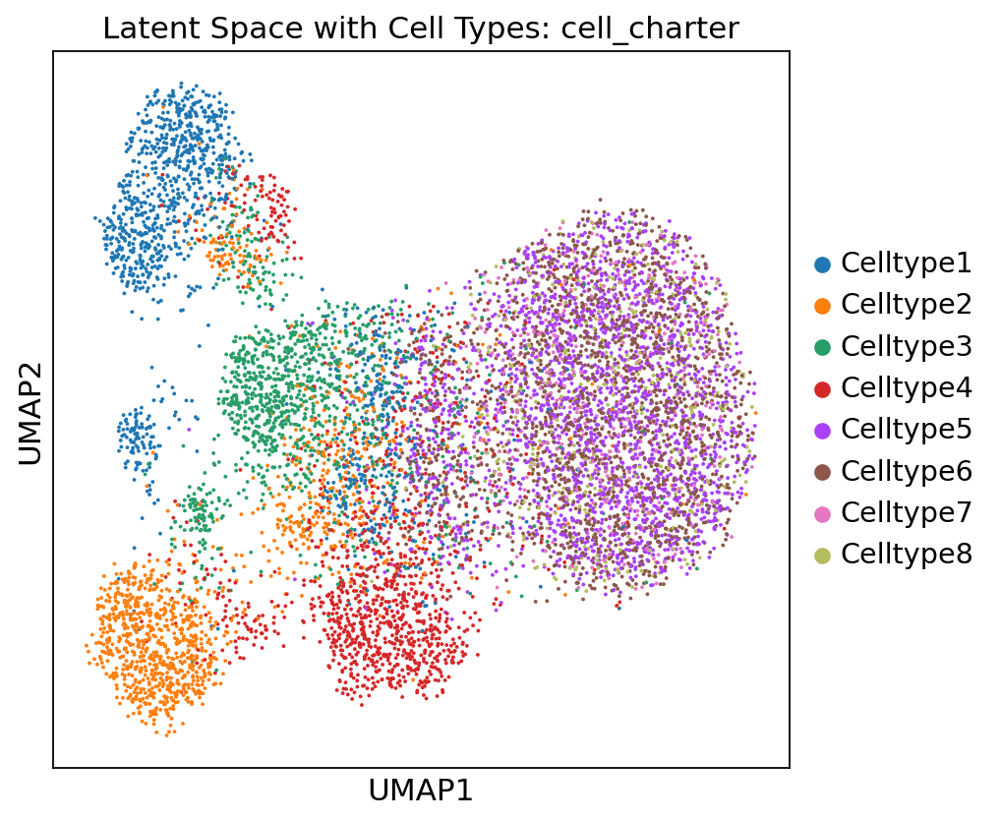

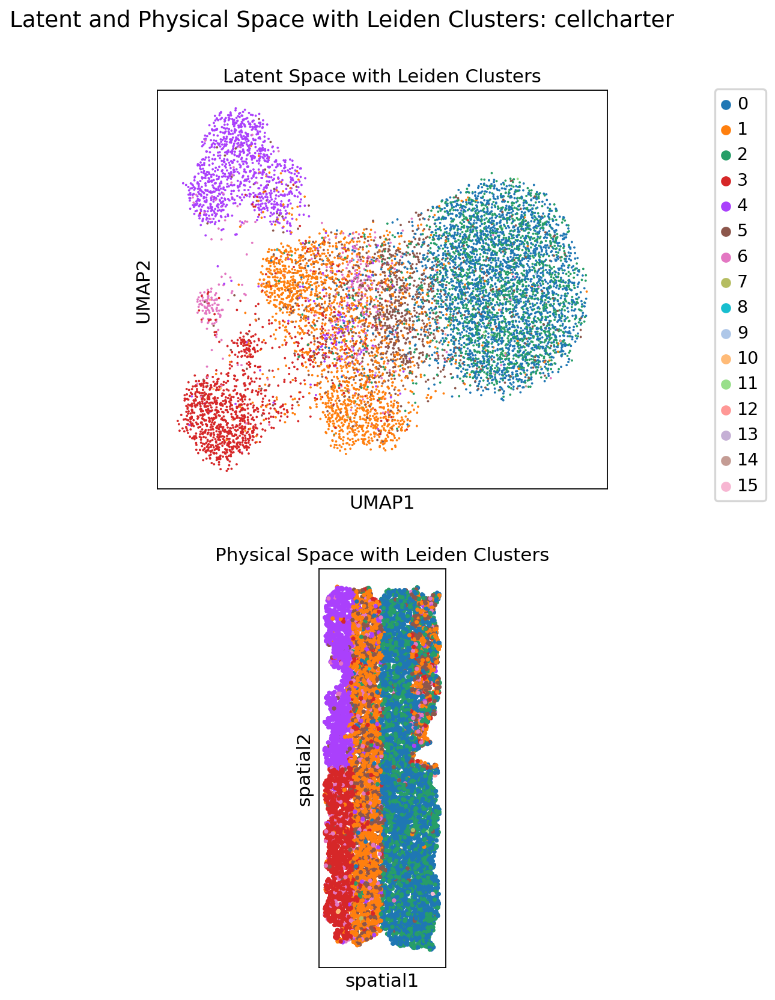

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


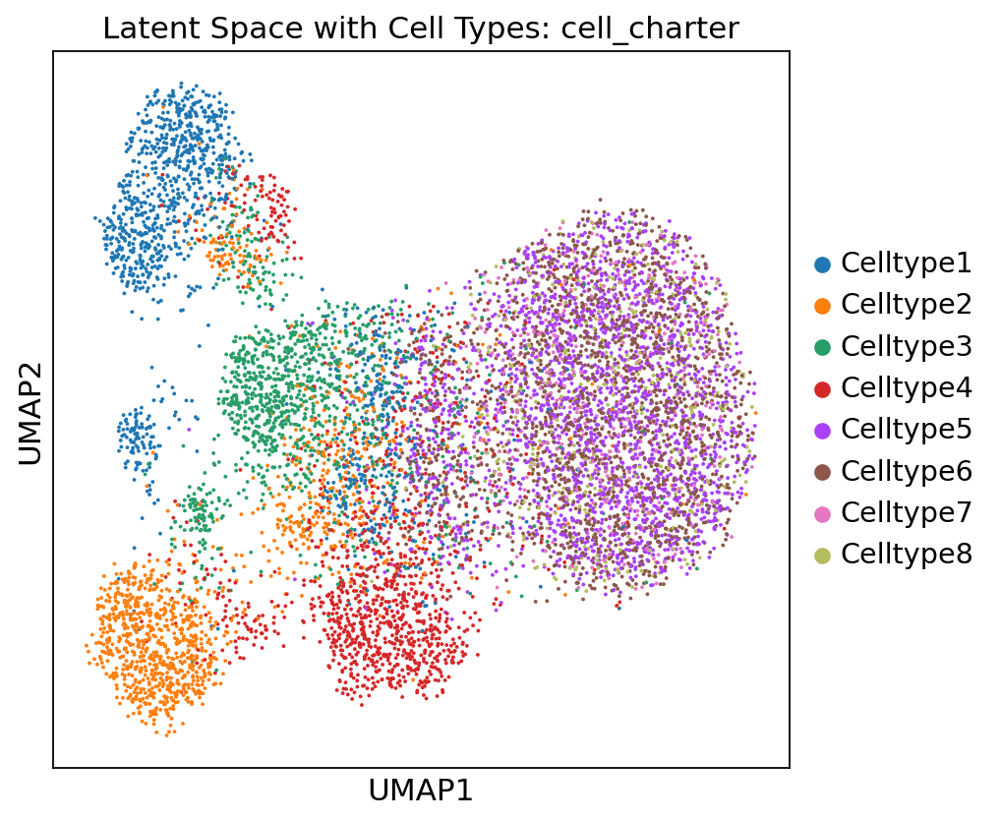

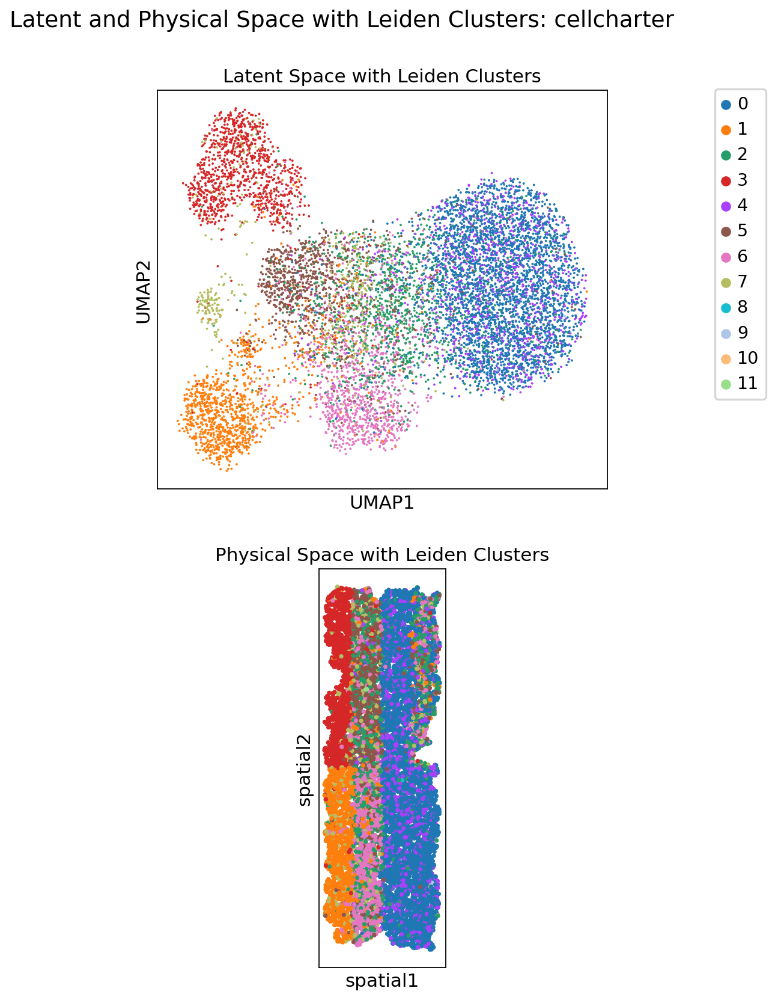

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


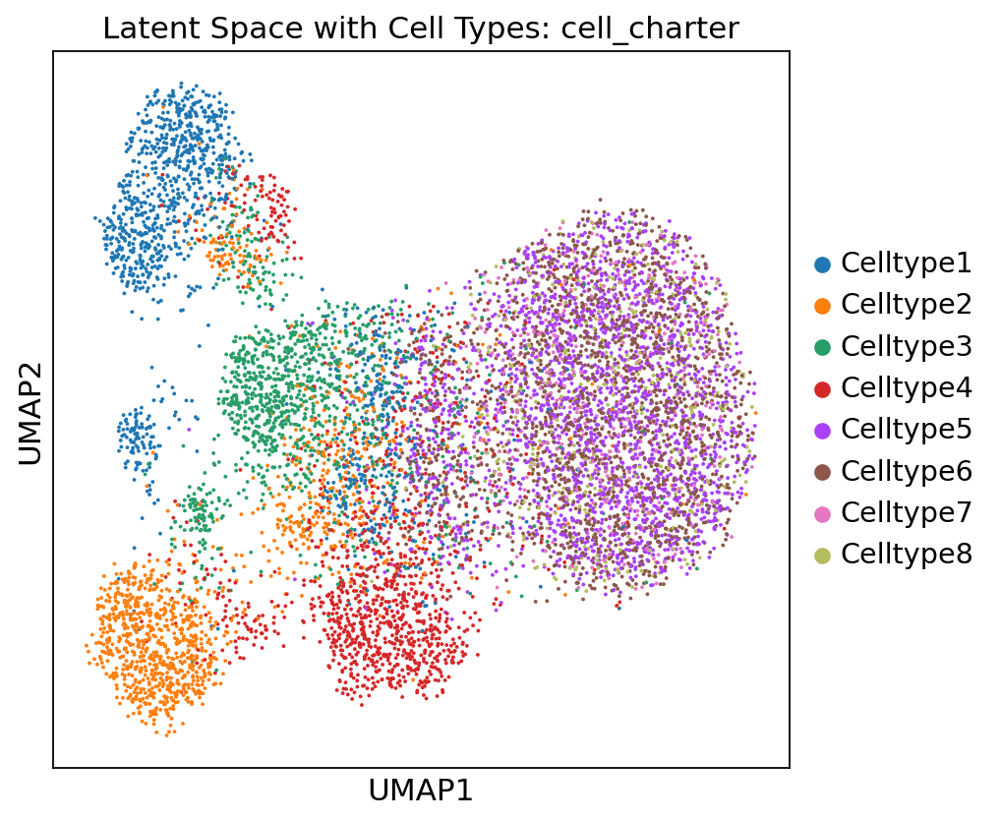

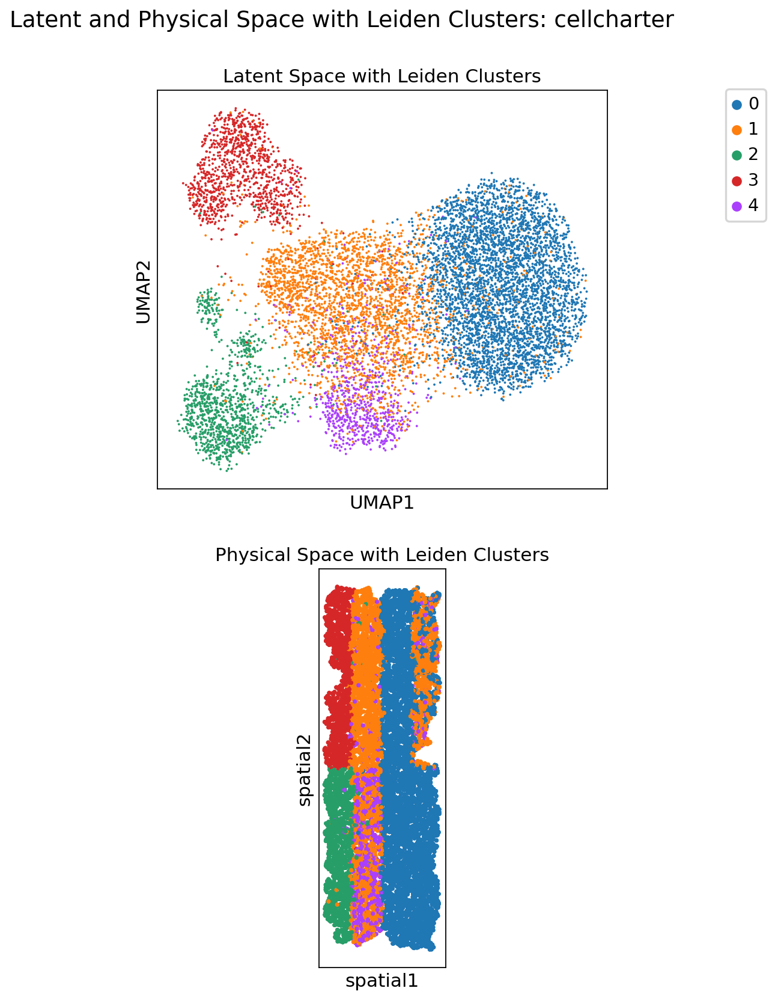

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


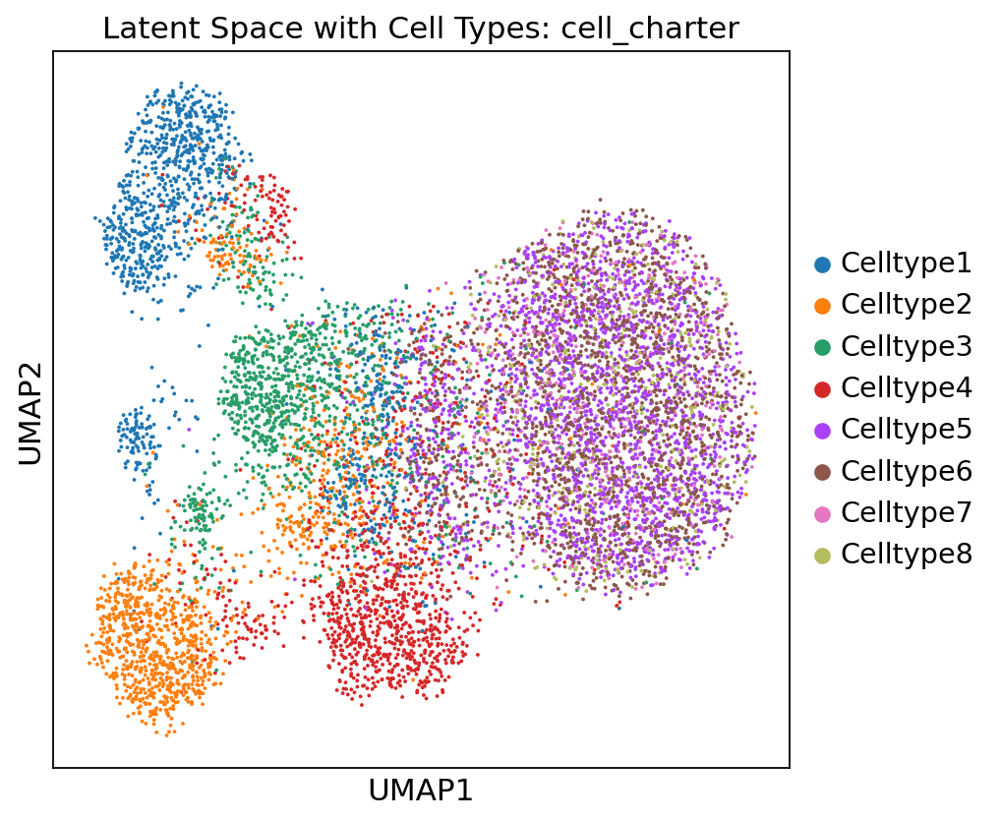

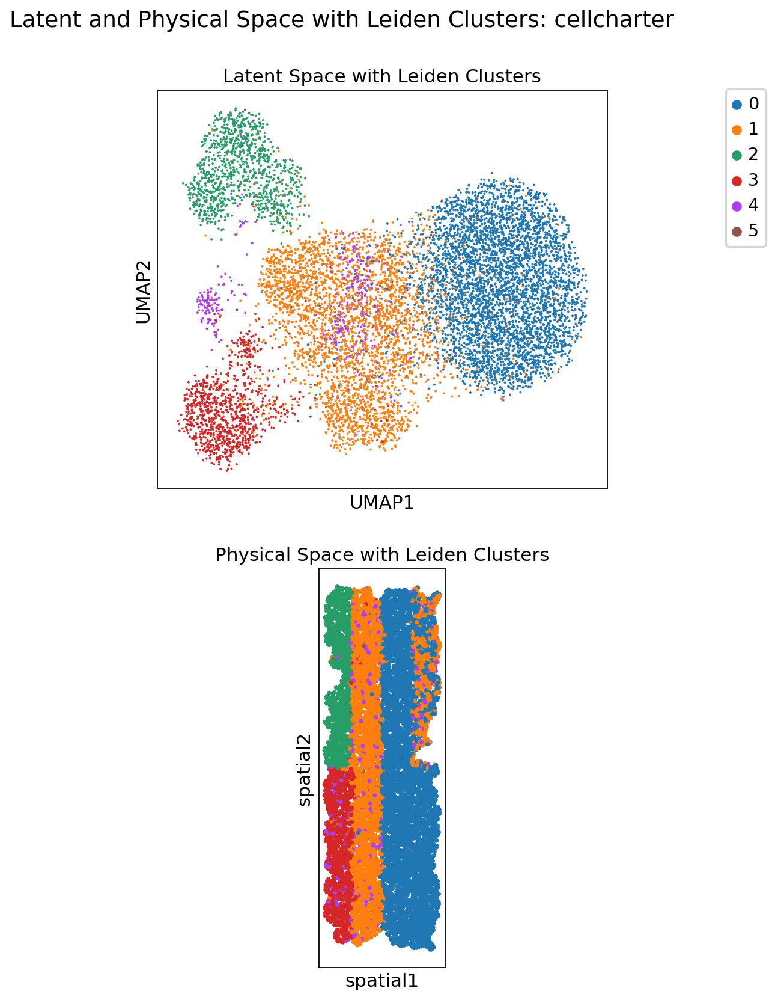

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


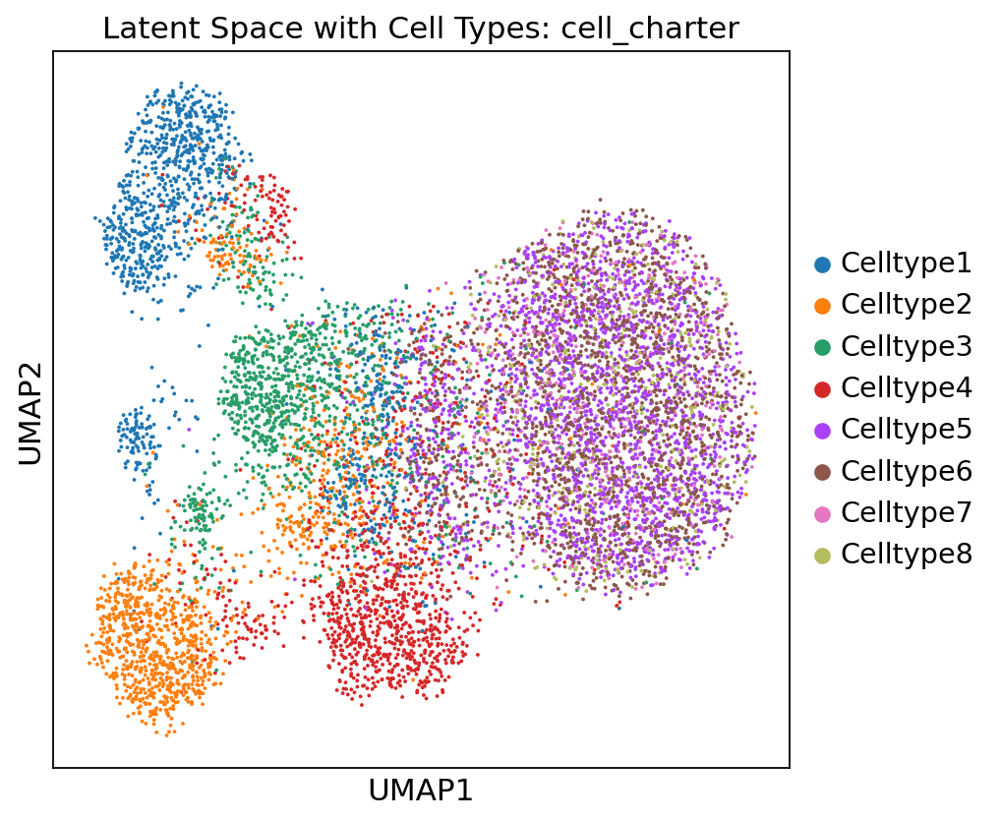

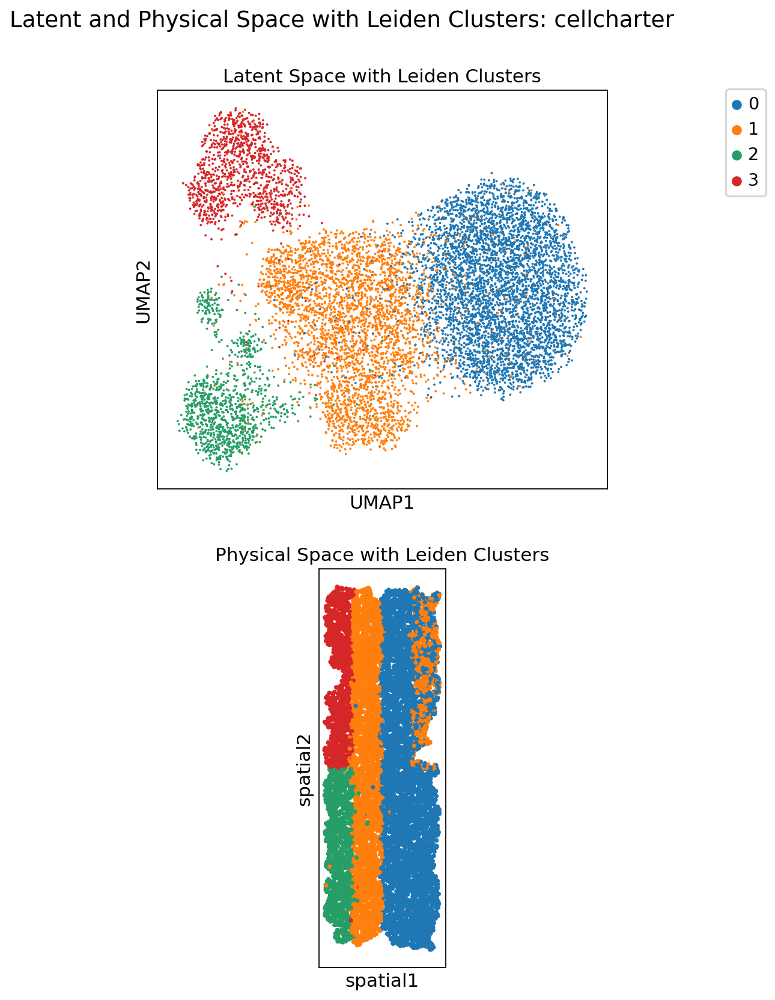

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


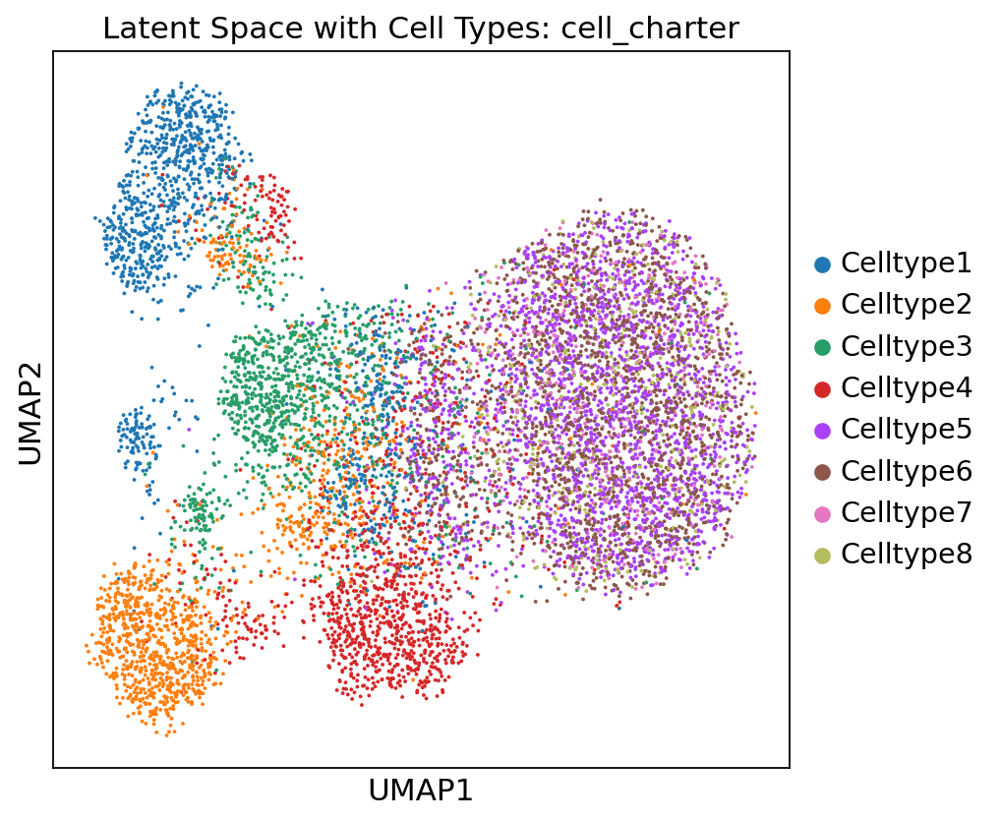

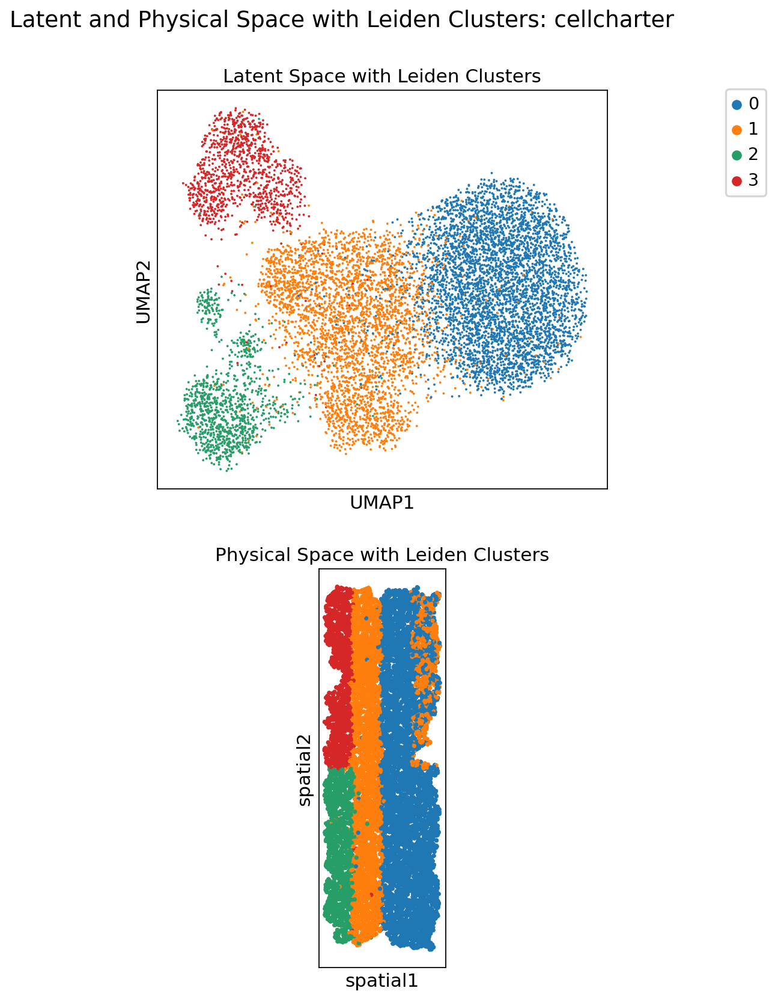

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


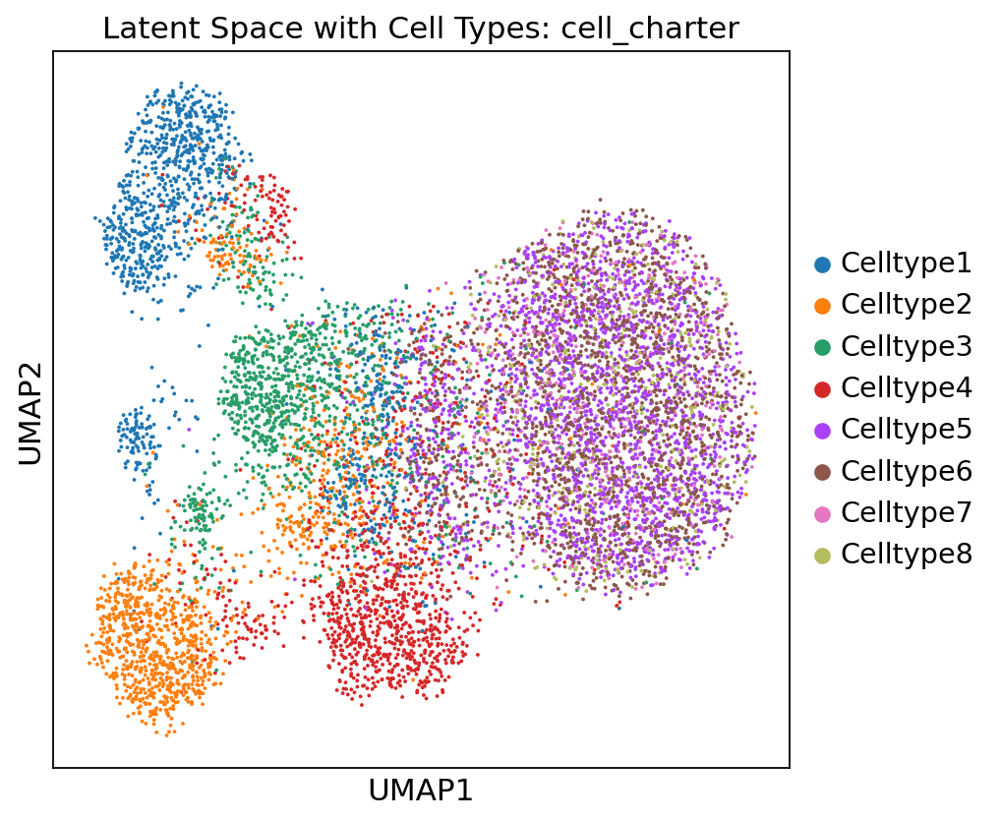

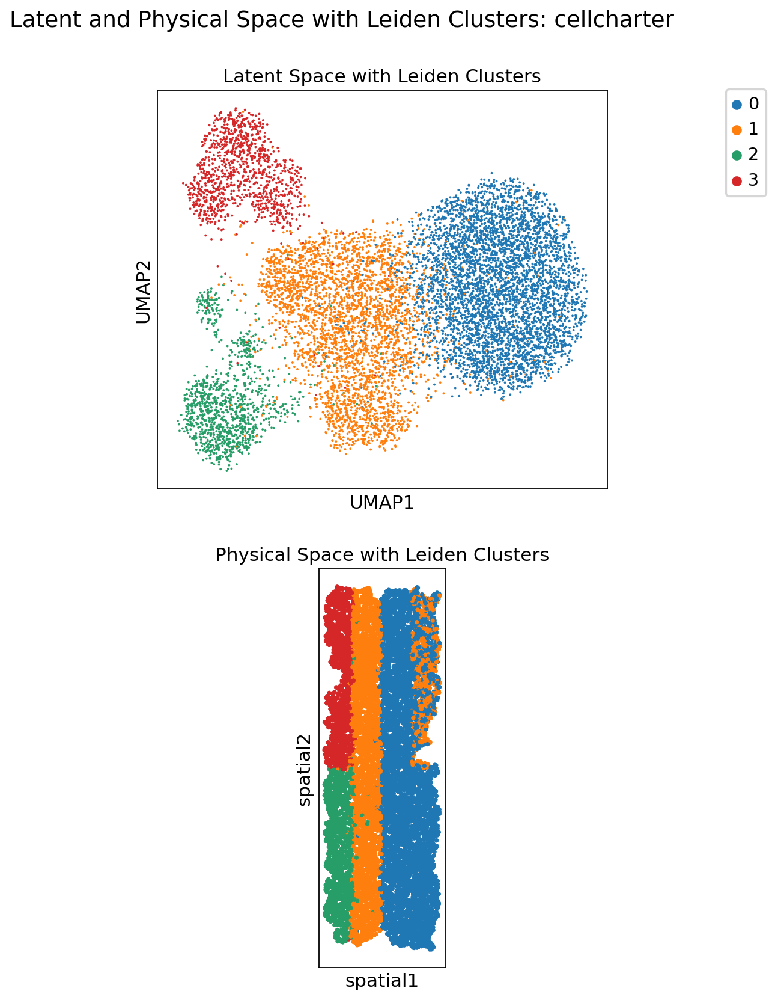

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


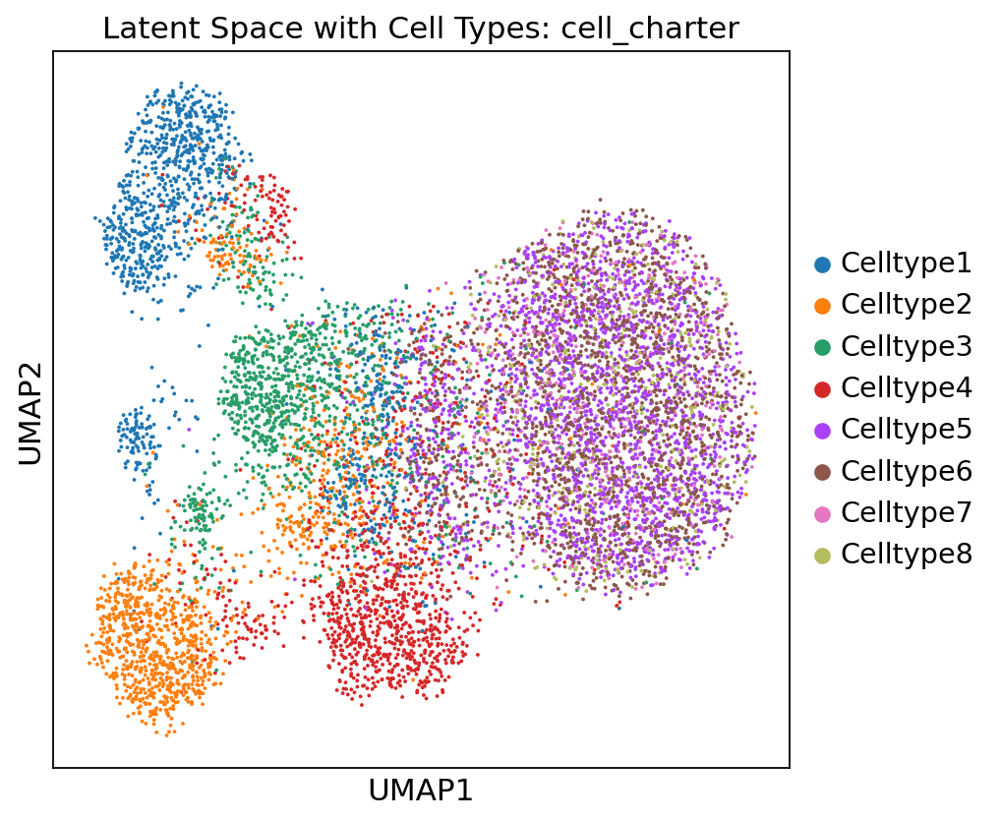

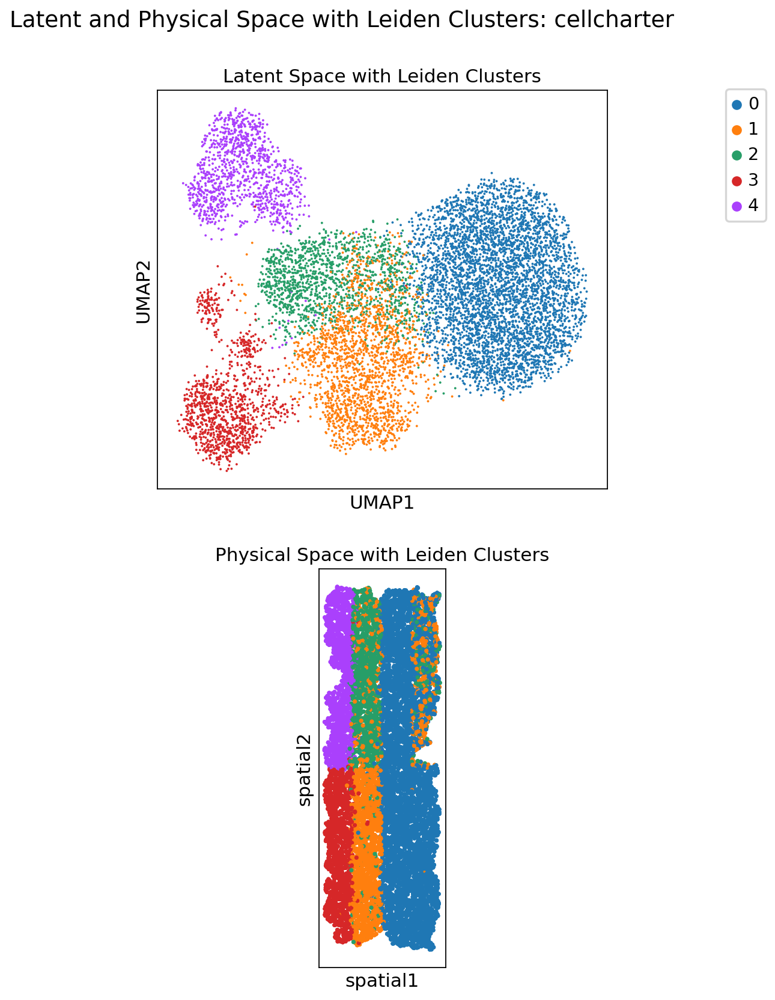

In [86]:
scvi_latent_adata = './sim_free_1354fts_10000locs_8r_8c_20p_3fc_scvi.h5ad'
adata = sc.read('./sim_free_1354fts_10000locs_8r_8c_20p_3fc.h5ad')
dataset_name = 'sim_free_1354fts_10000locs_8r_8c_20p_3fc'
label_cats = ["cell_types"]
cell_type_key = label_cats[0]
adata_new= train_cellcharter_models(adata, scvi_latent_adata, dataset_name,
                         cell_type_key,
                         adata_new=None,
                         n_start_run=1,
                         n_end_run=8,
                         n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16])
run_classifier(adata_new, ["cell_type"],dataset_name,  n_start_run=1, n_end_run=8)
get_clusters(adata_new,["cell_type"],dataset_name, n_start_run=1,
                             n_end_run=8,
                             n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16], plot_latent_umaps= True)


100%|██████████| 4/4 [00:00<00:00, 44.25it/s]


/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


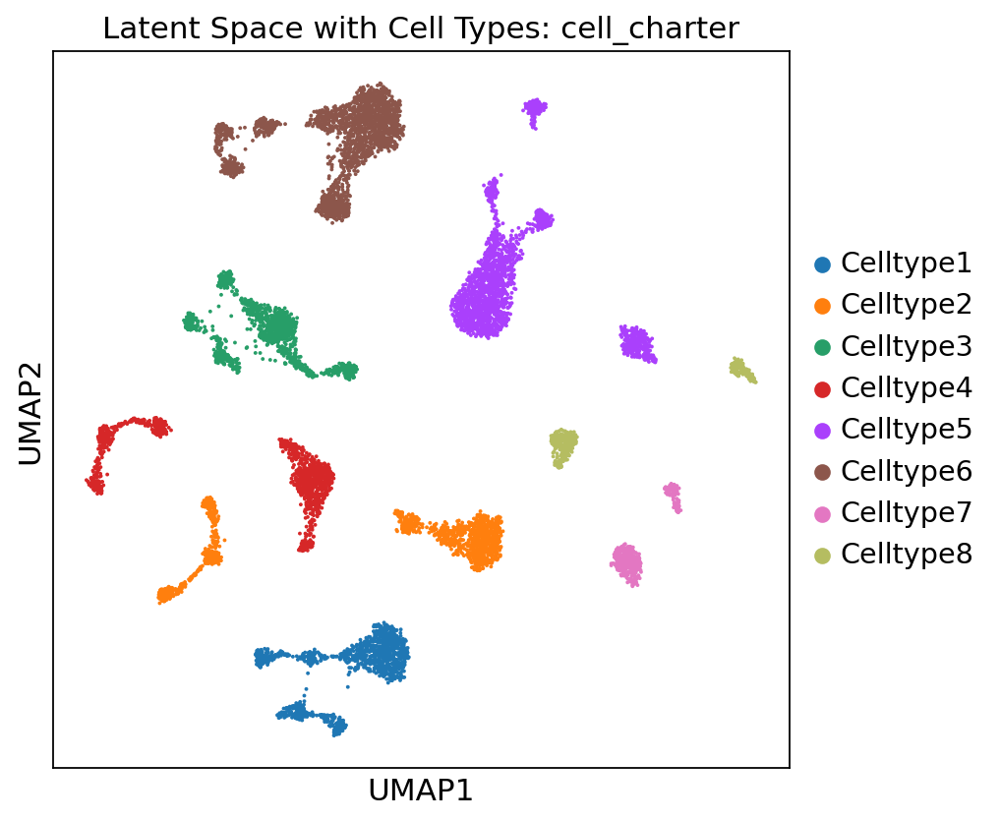

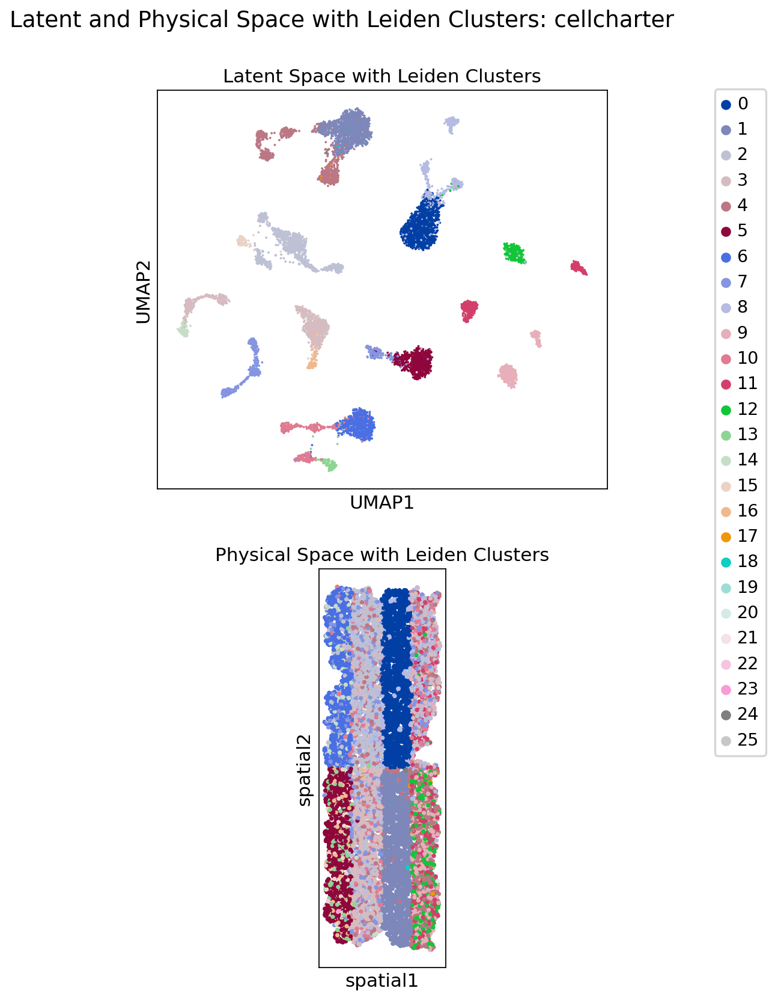

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


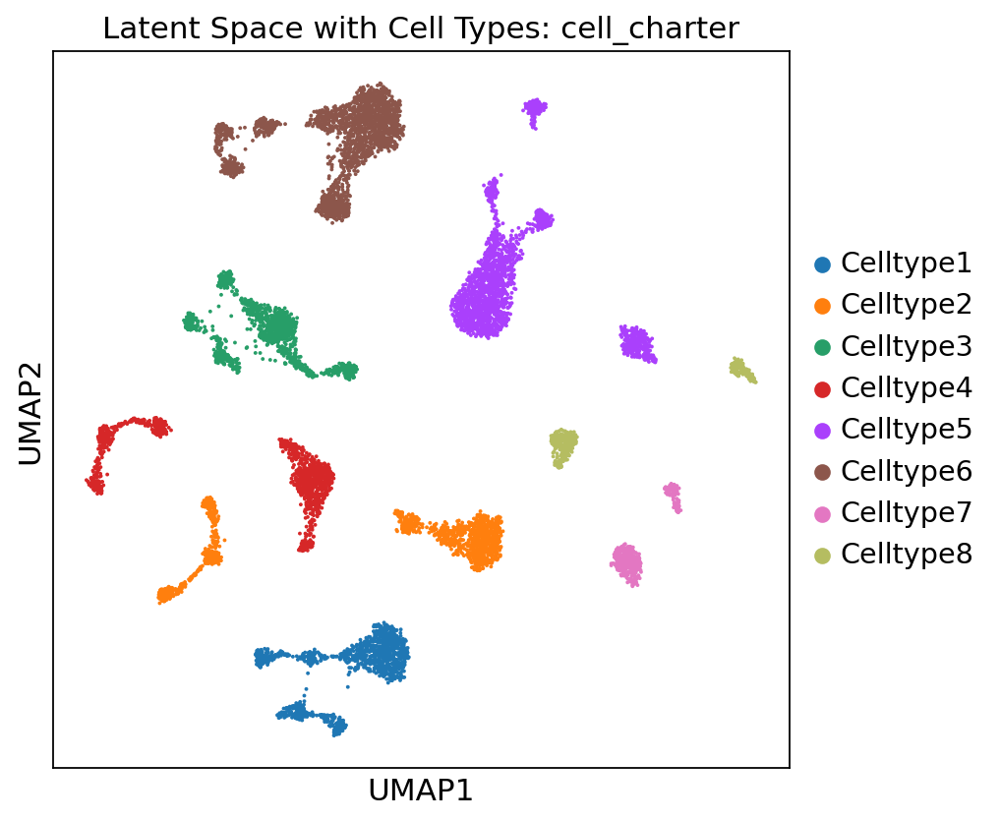

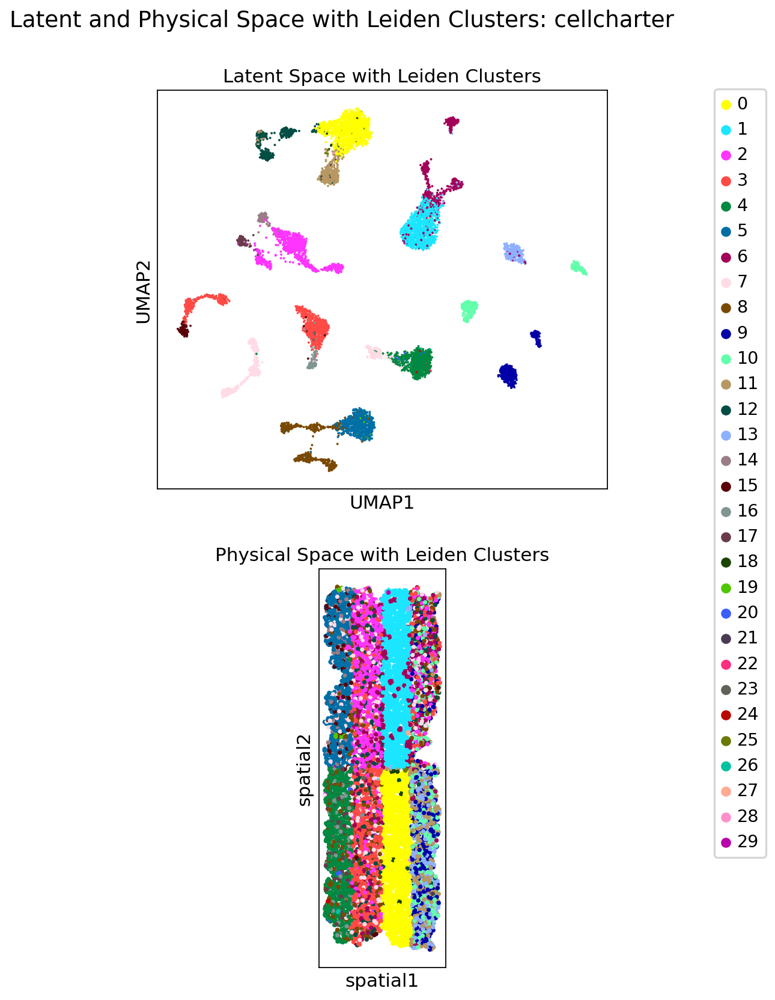

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


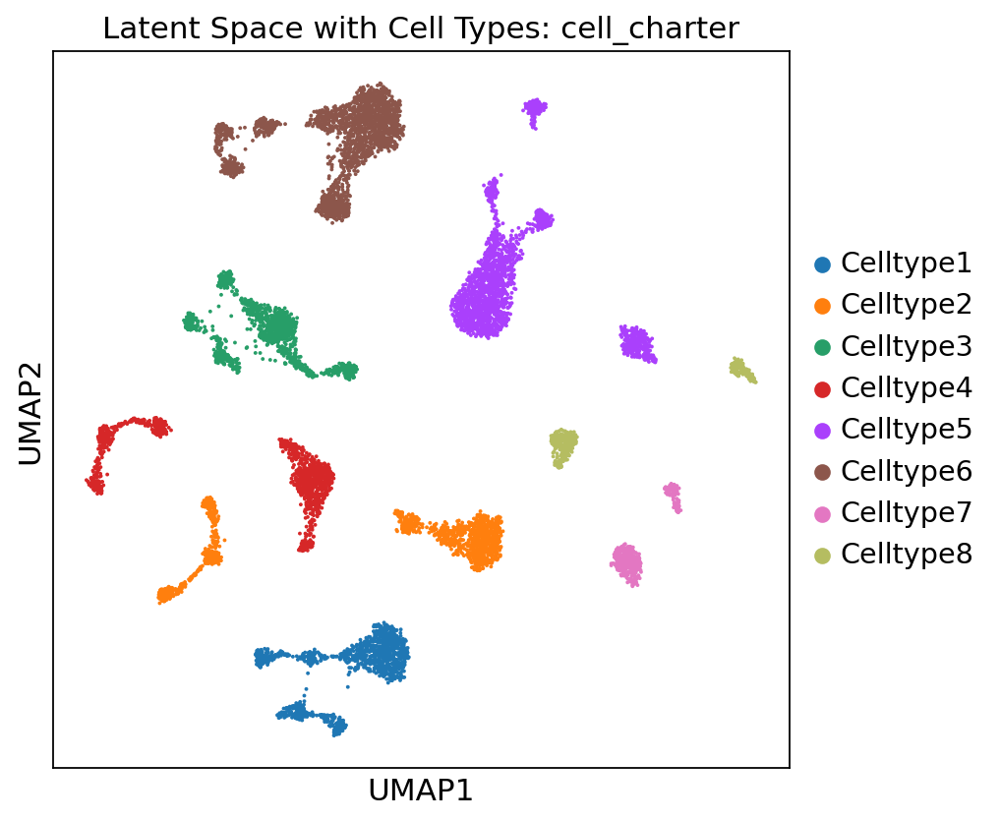

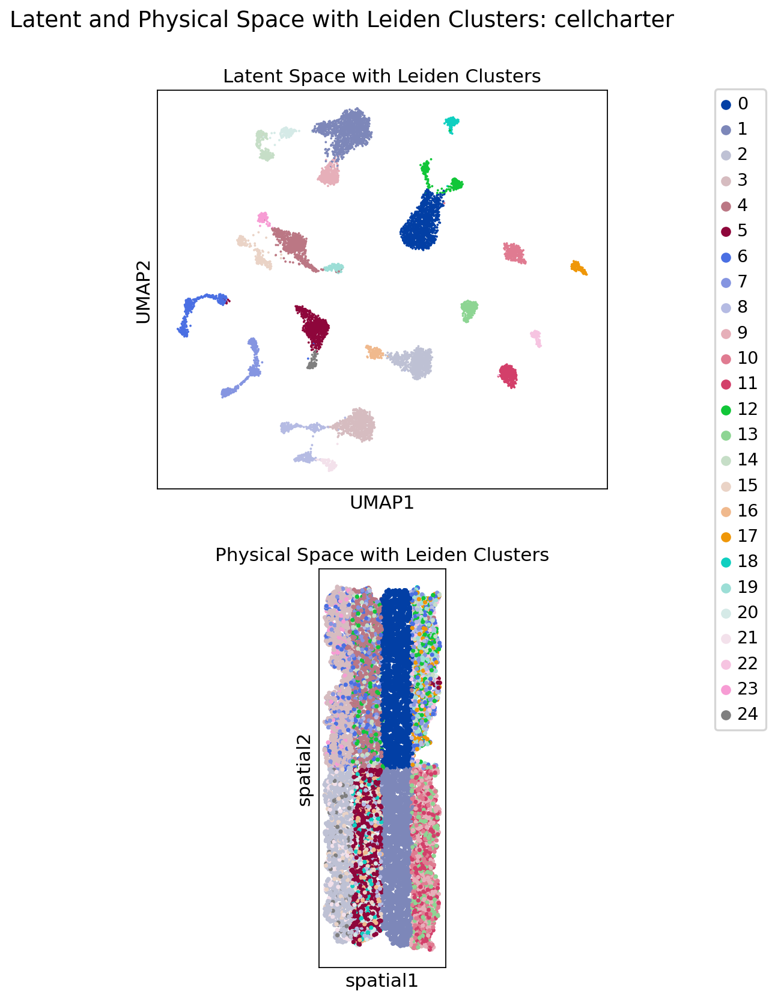

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


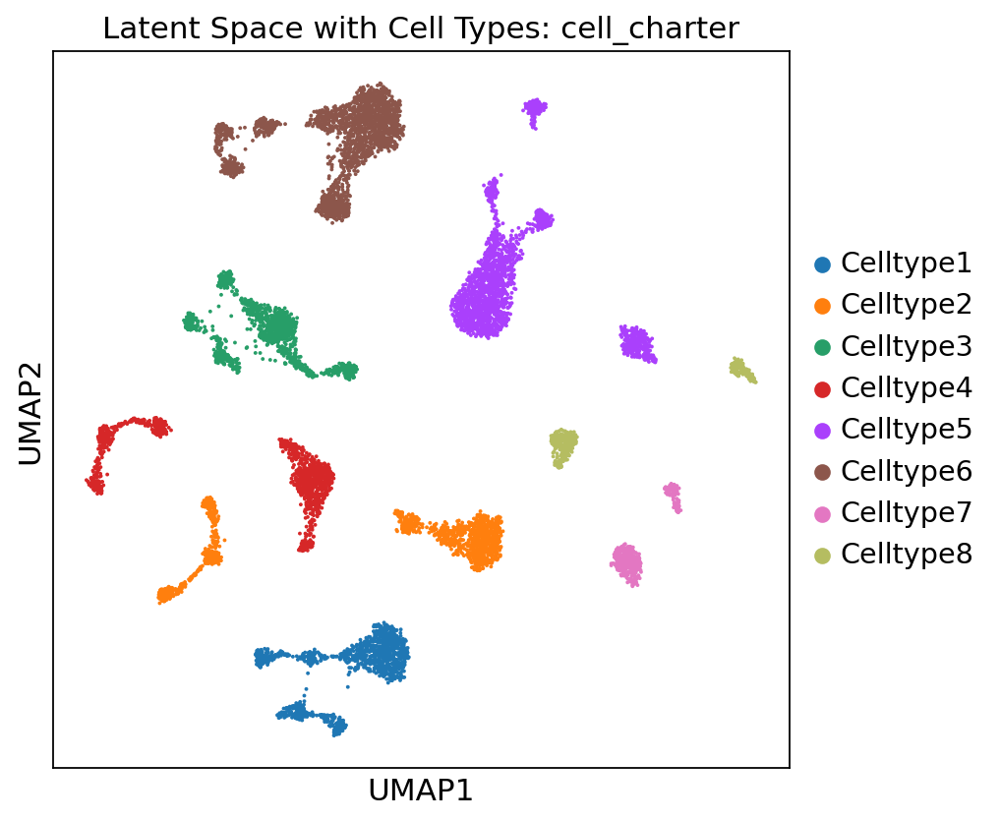

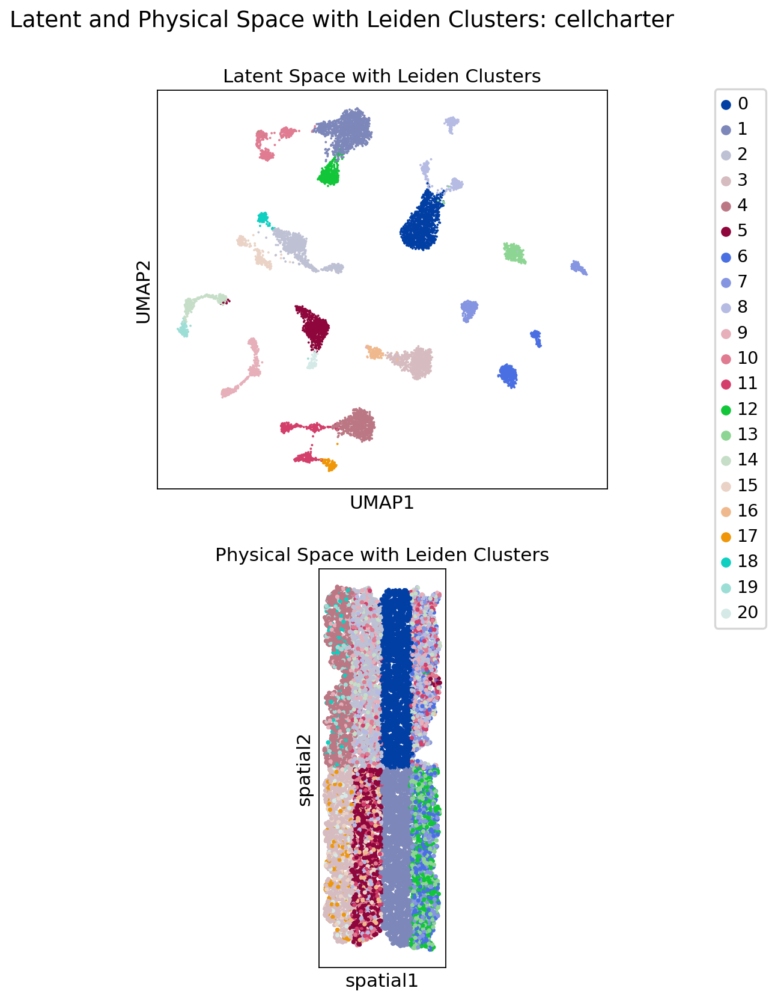

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


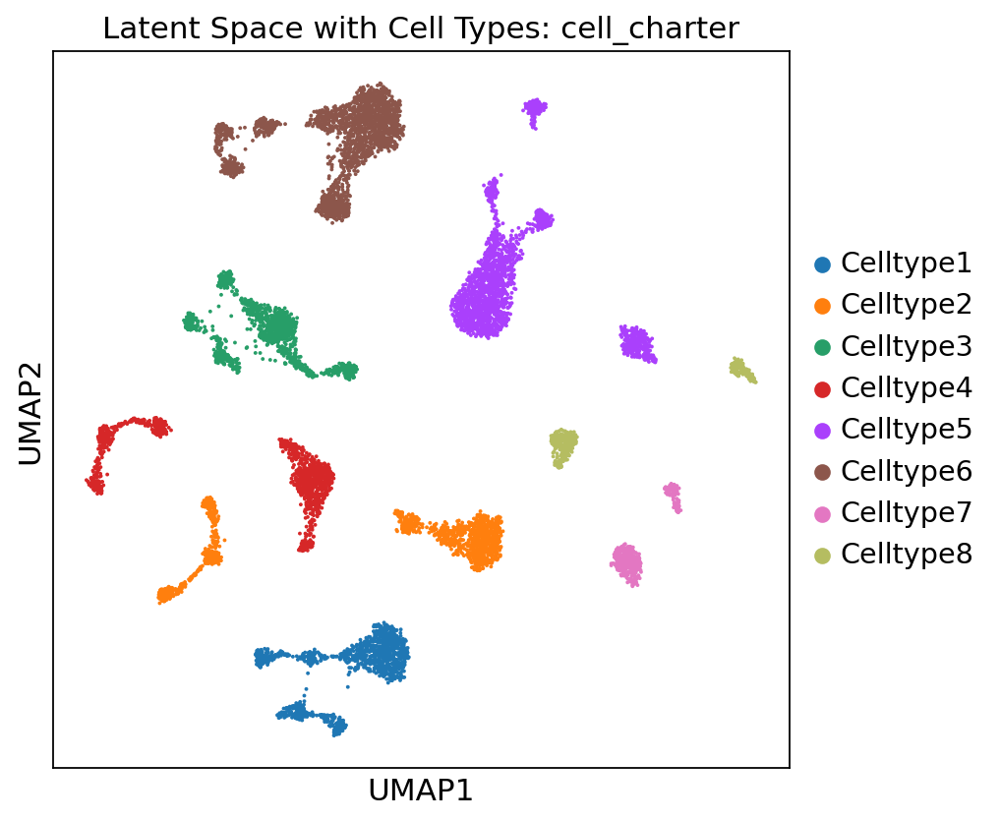

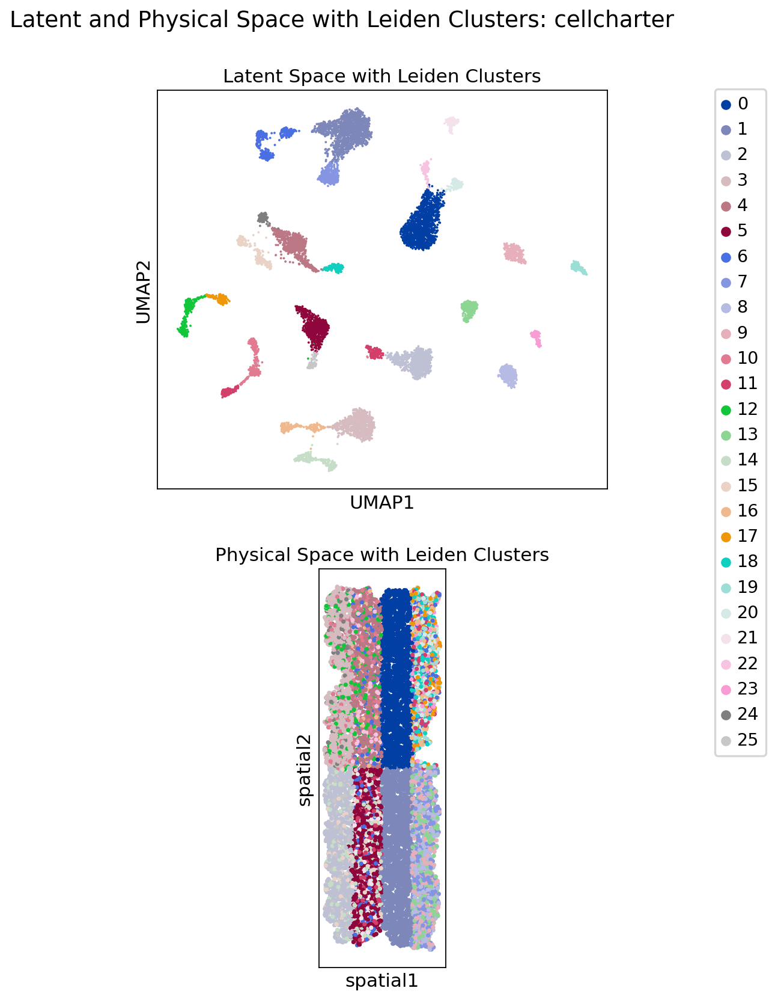

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


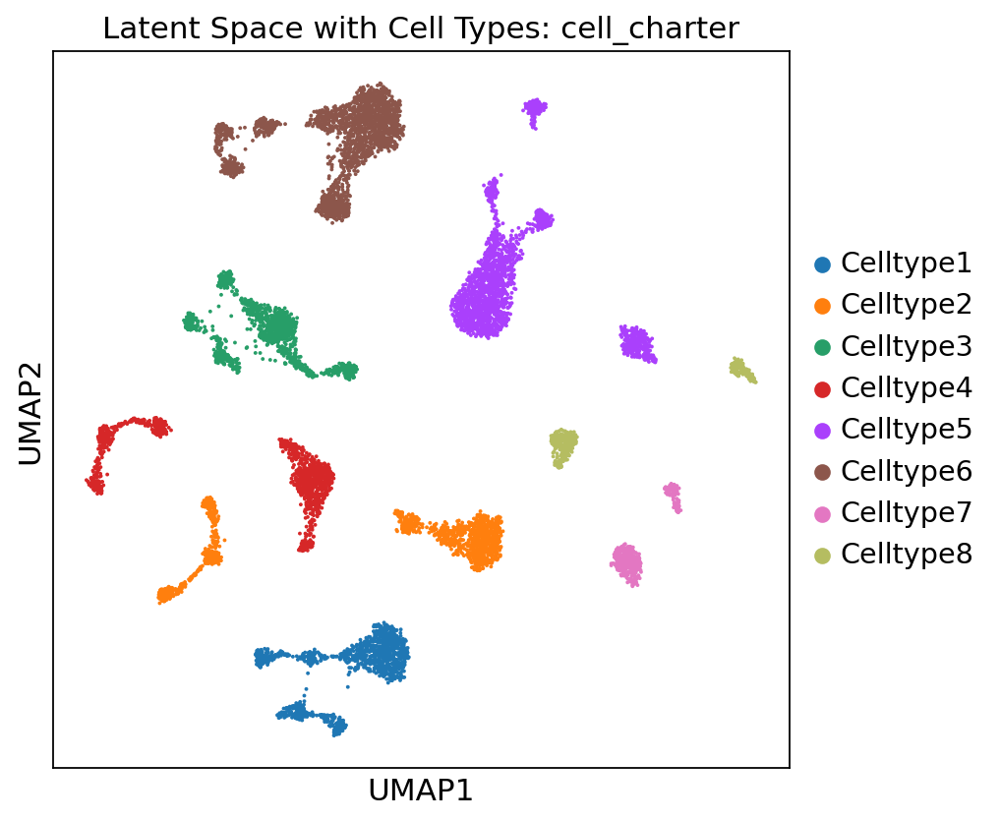

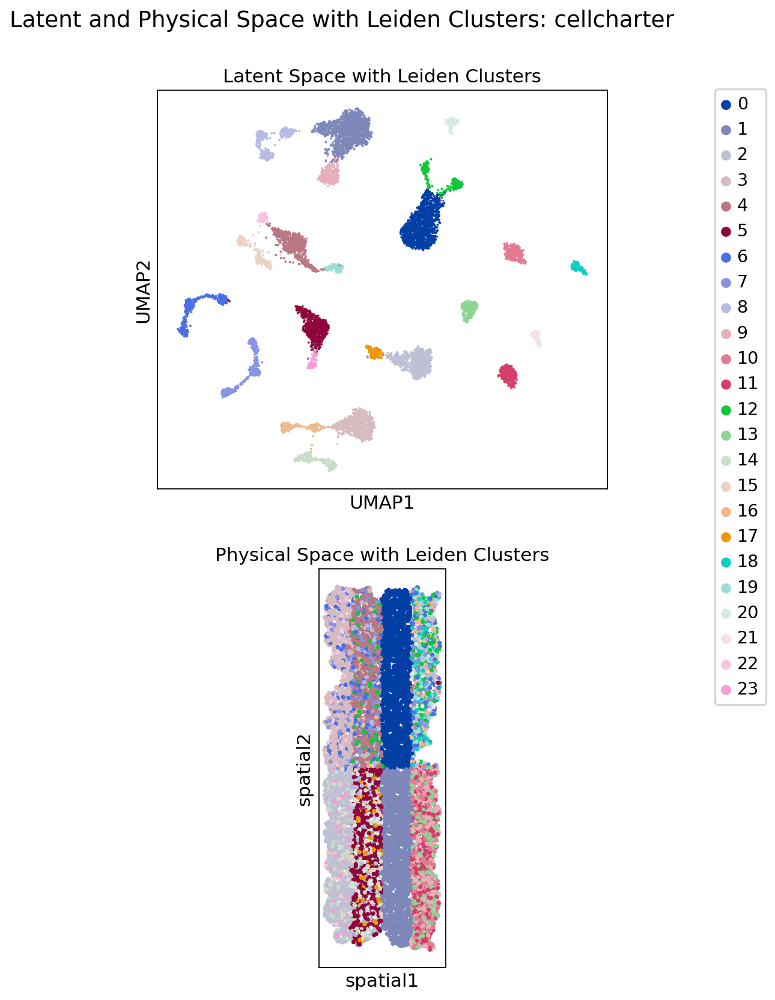

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


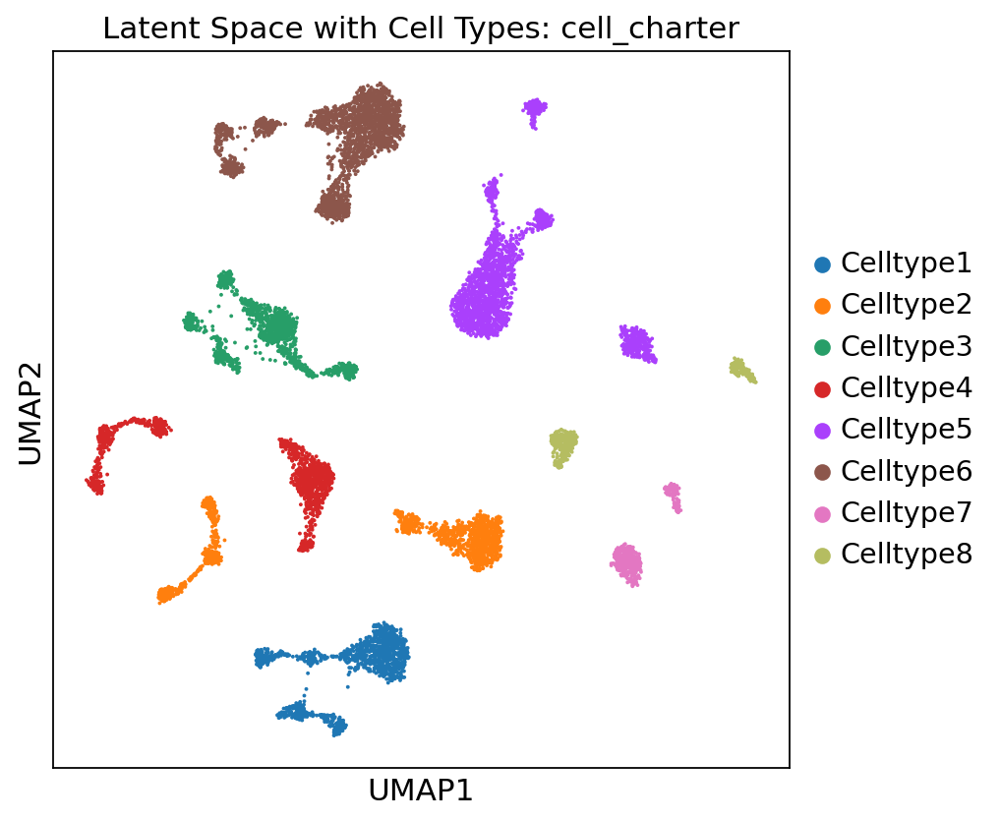

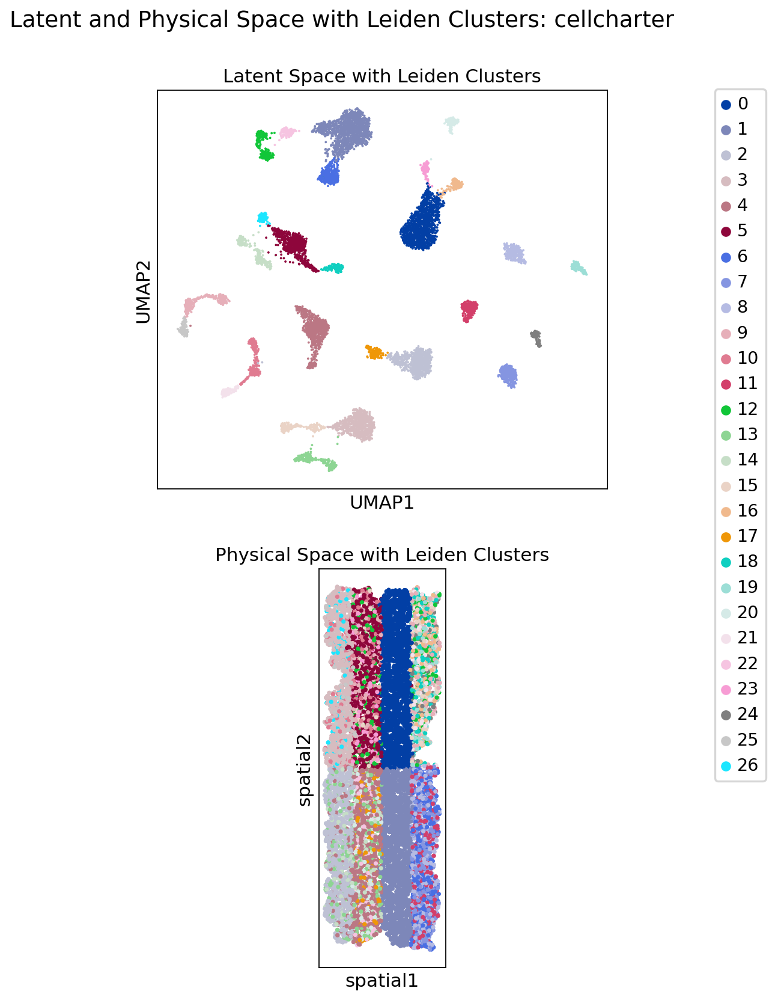

/nfs/users/nfs_a/ay8/miniconda3/envs/cellcharter-env/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


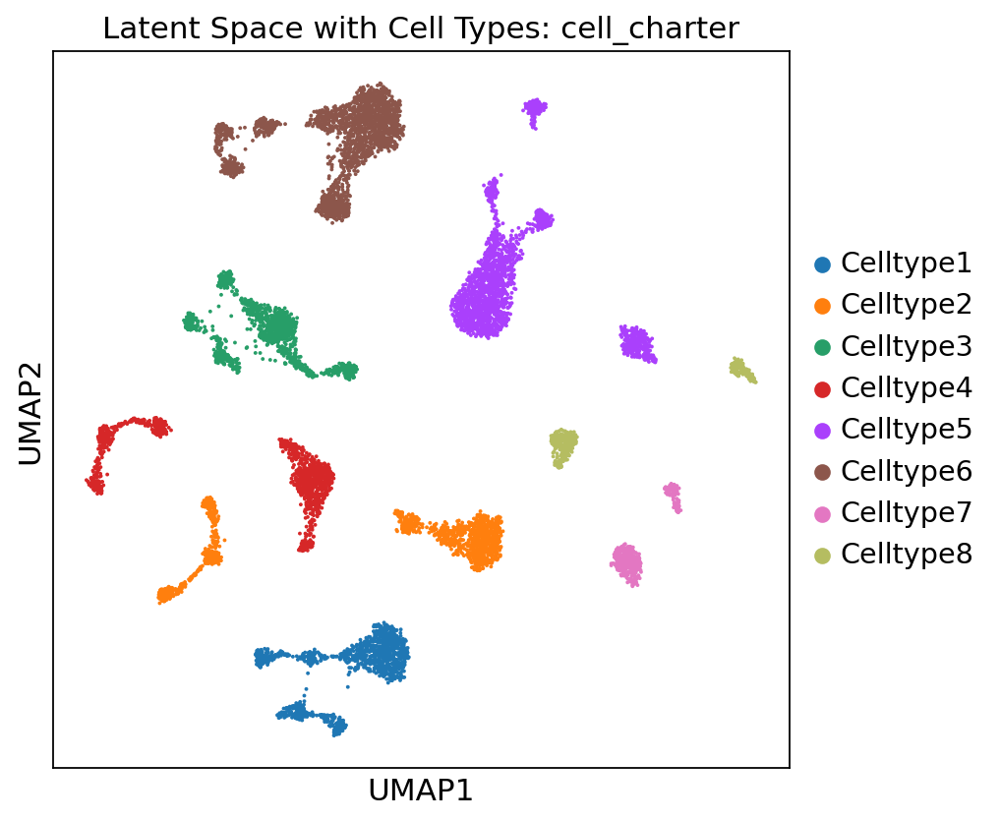

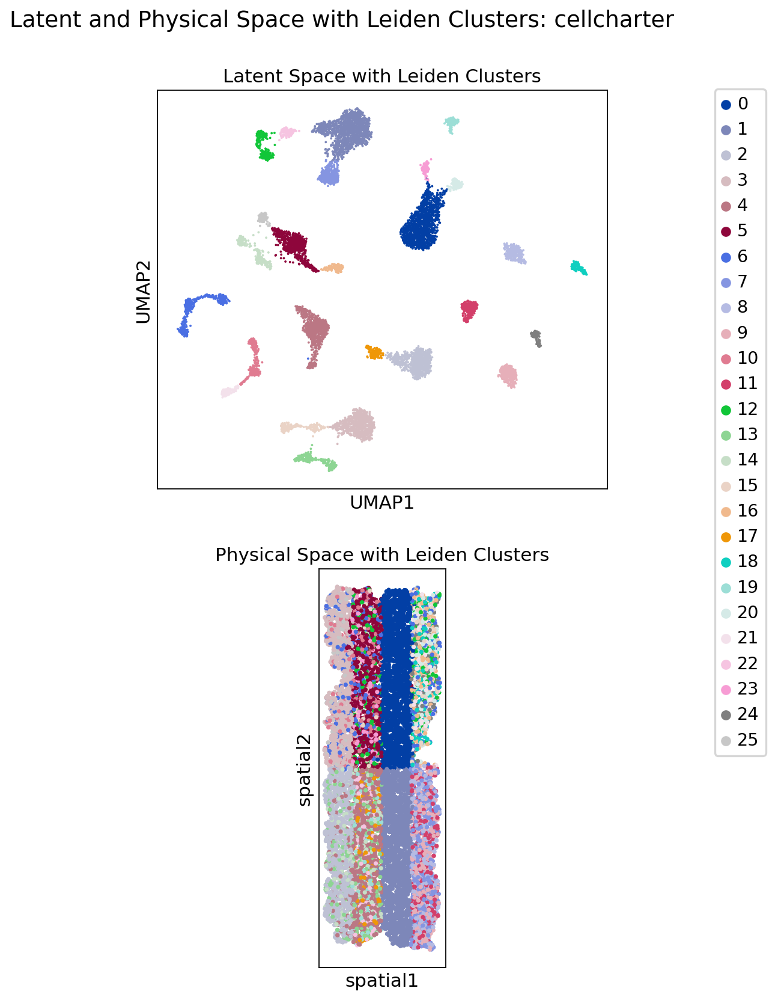

In [87]:
scvi_latent_adata = './sim_ref_1354fts_10000locs_8r_8c_20p_3fc_scvi.h5ad'
dataset_name = 'sim_ref_1354fts_10000locs_8r_8c_20p_3fc'
adata = sc.read('./sim_ref_1354fts_10000locs_8r_8c_20p_3fc.h5ad')
x_coordinates = adata.obs['x'].values
y_coordinates = adata.obs['y'].values
# Combine 'x' and 'y' into a single array of shape (n_obs, 2)
spatial_coordinates = np.vstack((x_coordinates, y_coordinates)).T
# Add the spatial coordinates to the obsm attribute
adata.obsm['spatial'] = spatial_coordinates
label_cats = ["cell_type"]
cell_type_key = label_cats[0]
adata_new= train_cellcharter_models(adata, scvi_latent_adata, dataset_name,
                         cell_type_key,
                         adata_new=None,
                         n_start_run=1,
                         n_end_run=8,
                         n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16])
run_classifier(adata_new, ["cell_type"],dataset_name,  n_start_run=1, n_end_run=8)
get_clusters(adata_new,["cell_type"],dataset_name, n_start_run=1,
                             n_end_run=8,
                             n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16], plot_latent_umaps= True)


In [1]:
scvi_latent_adata = './nanostring_cosmx_human_brain_scvi.h5ad'
dataset_name = 'nanostring_cosmx_human_brain'
adata = sc.read('./nanostring_cosmx_human_brain.h5ad')

spatial_coords = adata.obsm['spatial']
# Create DataFrame with x and y columns
spatial_df = pd.DataFrame(spatial_coords, columns=['x', 'y'], index=adata.obs.index)

# Add x and y columns to adata.obs
adata.obs['x'] = spatial_df['x']
adata.obs['y'] = spatial_df['y']
label_cats = ["cell_type", "niche_type"]
cell_type_key = label_cats[0]
adata_new= train_cellcharter_models(adata, scvi_latent_adata, dataset_name,
                         cell_type_key,
                         adata_new=None,
                         n_start_run=1,
                         n_end_run=8,
                         n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16])
run_classifier(adata_new, ["cell_type"],dataset_name,  n_start_run=1, n_end_run=8)
get_clusters(adata_new,["cell_type"],dataset_name, n_start_run=1,
                             n_end_run=8,
                             n_neighbor_list=[4, 4, 8, 8, 12, 12, 16, 16], plot_latent_umaps= True)


NameError: name 'sc' is not defined